# Week 6: Clustering Analysis

This notebook applies K-means clustering to the saved Week 5
TF-IDF matrix.

The analysis will evaluate silhouette scores for K=2–8 and interpret
the selected clusters using their terms and representative documents.

## Load and Validate the Clustering Inputs

Load the saved TF-IDF matrix, document index, vocabulary index,
and prepared Week 6 corpus using relative paths.

The document index identifies each matrix row, while the vocabulary
index identifies each matrix column. Align the corpus to the matrix
row order using document IDs.

In [1]:
import numpy as np
import pandas as pd

from scipy.sparse import load_npz

# Load the saved matrix and its row/column mappings.
tfidf_matrix = load_npz(
    "data/tfidf_baseline_v1/W05_TFIDF_Matrix.npz"
)

document_index = pd.read_csv(
    "data/tfidf_baseline_v1/W05_TFIDF_Document_Index.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
).sort_values("matrix_row").reset_index(drop=True)

vocabulary_index = pd.read_csv(
    "data/tfidf_baseline_v1/W05_TFIDF_Vocabulary_Index.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
).sort_values("matrix_column").reset_index(drop=True)

clustering_corpus = pd.read_csv(
    "data/week6_inputs/W06_Analysis_Input.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Validate the matrix dimensions and mappings.
assert tfidf_matrix.shape == (
    len(document_index), len(vocabulary_index)
), "Matrix dimensions do not match the index files."

assert document_index["matrix_row"].tolist() == \
    list(range(tfidf_matrix.shape[0])), "Invalid matrix row mapping."

assert vocabulary_index["matrix_column"].tolist() == \
    list(range(tfidf_matrix.shape[1])), "Invalid matrix column mapping."

assert document_index["document_id"].is_unique
assert clustering_corpus["document_id"].is_unique

assert set(document_index["document_id"]) == \
    set(clustering_corpus["document_id"]), "Document IDs do not match."

assert np.isfinite(tfidf_matrix.data).all(), \
    "The matrix contains non-finite values."

# Align the corpus to the matrix row order.
clustering_corpus = (
    clustering_corpus
    .set_index("document_id")
    .loc[document_index["document_id"].tolist()]
    .reset_index()
)

print("Clustering input validation passed.")
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Aligned documents:", len(clustering_corpus))
print("Vocabulary terms:", len(vocabulary_index))

Clustering input validation passed.
TF-IDF matrix shape: (20, 2441)
Aligned documents: 20
Vocabulary terms: 2441


## Compare K-Means Cluster Solutions

Compare K = 2–8 using the validated Week 5 TF-IDF matrix.
Use a fixed random seed and 20 initializations for reproducibility.

Select the solution with the highest Euclidean silhouette score,
which measures separation between clusters relative to their internal
distances. Interpret the result as exploratory given the small corpus.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.sparse import load_npz
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load the saved matrix using a portable relative path.
X_clustering = load_npz(
    Path("data")
    / "tfidf_baseline_v1"
    / "W05_TFIDF_Matrix.npz"
)

assert X_clustering.shape == (20, 2441)
assert np.isfinite(X_clustering.data).all()
assert (X_clustering.getnnz(axis=1) > 0).all()

CLUSTER_RANDOM_STATE = 42
CLUSTER_N_INIT = 20

kmeans_models = {}
cluster_comparison_rows = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=CLUSTER_RANDOM_STATE,
        n_init=CLUSTER_N_INIT,
        max_iter=300,
        algorithm="lloyd"
    )

    labels = model.fit_predict(X_clustering)
    cluster_ids, sizes = np.unique(labels, return_counts=True)

    assert len(cluster_ids) == k, (
        f"K={k} produced fewer than {k} distinct clusters."
    )

    score = silhouette_score(
        X_clustering,
        labels,
        metric="euclidean"
    )

    kmeans_models[k] = model

    cluster_comparison_rows.append({
        "k": k,
        "silhouette_score": score,
        "inertia": model.inertia_,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "singleton_clusters": int((sizes == 1).sum())
    })

cluster_comparison = pd.DataFrame(cluster_comparison_rows)

# Highest silhouette wins; use smaller K if scores tie exactly.
selected_k = int(
    cluster_comparison.sort_values(
        ["silhouette_score", "k"],
        ascending=[False, True]
    ).iloc[0]["k"]
)

selected_kmeans = kmeans_models[selected_k]

display(cluster_comparison.round(4))
print(f"Selected K: {selected_k}")
print(
    "Selected silhouette score:",
    f"{cluster_comparison.set_index('k').loc[selected_k, 'silhouette_score']:.4f}"
)

,k,silhouette_score,inertia,smallest_cluster,largest_cluster,singleton_clusters
0,2,0.0428,14.0712,10,10,0
1,3,0.0459,13.0771,3,10,0
2,4,0.0496,12.1655,2,10,0
3,5,0.0558,11.1268,1,10,1
4,6,0.0424,10.0954,1,6,1
5,7,0.0400,9.3804,1,8,3
6,8,0.0361,8.4102,1,5,3


Selected K: 5
Selected silhouette score: 0.0558


## Inspect Cluster Sizes and Top Terms

K = 5 achieved the highest silhouette score among the tested candidates.
The score of 0.0558 indicates weak separation, so cluster interpretations
remain exploratory.

Align document metadata with the TF-IDF matrix by its saved row index.
Describe each cluster using the ten terms with the highest centroid
TF-IDF weights. These terms summarize clusters rather than explain
causal differences.

In [3]:
# Load document and vocabulary indexes in matrix order.
document_index = pd.read_csv(
    Path("data")
    / "tfidf_baseline_v1"
    / "W05_TFIDF_Document_Index.csv",
    encoding="utf-8-sig",
    keep_default_na=False
).sort_values("matrix_row").reset_index(drop=True)

vocabulary_index = pd.read_csv(
    Path("data")
    / "tfidf_baseline_v1"
    / "W05_TFIDF_Vocabulary_Index.csv",
    encoding="utf-8-sig",
    keep_default_na=False
).sort_values("matrix_column").reset_index(drop=True)

prepared_documents = pd.read_csv(
    Path("data") / "week6_inputs" / "W06_Analysis_Input.csv",
    encoding="utf-8-sig",
    keep_default_na=False
)

# Check alignment before attaching cluster labels.
assert np.array_equal(
    document_index["matrix_row"].to_numpy(),
    np.arange(X_clustering.shape[0])
)

assert np.array_equal(
    vocabulary_index["matrix_column"].to_numpy(),
    np.arange(X_clustering.shape[1])
)

assert document_index["document_id"].is_unique
assert prepared_documents["document_id"].is_unique
assert set(document_index["document_id"]) == set(
    prepared_documents["document_id"]
)

cluster_documents = document_index[
    ["matrix_row", "document_id"]
].merge(
    prepared_documents,
    on="document_id",
    how="left",
    validate="one_to_one"
).sort_values("matrix_row").reset_index(drop=True)

cluster_documents["cluster"] = selected_kmeans.labels_

terms = vocabulary_index["term"].to_numpy()
cluster_profile_rows = []

for cluster_id in range(selected_k):
    centroid = selected_kmeans.cluster_centers_[cluster_id]

    top_positions = np.argsort(
        -centroid,
        kind="stable"
    )[:10]

    cluster_profile_rows.append({
        "cluster": cluster_id,
        "document_count": int(
            cluster_documents["cluster"].eq(cluster_id).sum()
        ),
        "top_10_terms": ", ".join(terms[top_positions])
    })

cluster_profiles = pd.DataFrame(cluster_profile_rows)

assert cluster_profiles["document_count"].sum() == len(
    cluster_documents
)

with pd.option_context("display.max_colwidth", None):
    display(cluster_profiles)

,cluster,document_count,top_10_terms
0,0,1,"dog, cat, robotic, animal, sally, dementia, capital, veteran, anne, mary"
1,1,10,"parent, support, senior, daily, help, care, emotional, feel, stay, not"
2,2,3,"worker, bot, care, sensor, ingrid, clinical, system, tom, data, decision"
3,3,2,"nysofa, york, intuition, partner, office, pilot, new, robotics, combat, association"
4,4,4,"robot, however, intuition, niemiec, robotics, bit, say, not, little, thing"


## Inspect Representative Documents

Select up to three documents nearest to each cluster centroid using
Euclidean distance in the original TF-IDF space.

Review their titles, publishers, and text previews alongside the top
terms before assigning descriptive cluster names. Centroid proximity
indicates a typical vector representation, not source quality or
business importance. Small clusters may contain fewer than three examples.

In [4]:
# Distance from every document to every cluster centroid.
cluster_distances = selected_kmeans.transform(X_clustering)

cluster_documents["distance_to_centroid"] = cluster_distances[
    np.arange(len(cluster_documents)),
    cluster_documents["cluster"].to_numpy(dtype=int)
]

representative_rows = []

for cluster_id in range(selected_k):
    members = cluster_documents.loc[
        cluster_documents["cluster"].eq(cluster_id)
    ].sort_values(
        ["distance_to_centroid", "document_id"]
    )

    representatives = members.head(3)

    for rank, (_, document) in enumerate(
        representatives.iterrows(),
        start=1
    ):
        representative_rows.append({
            "cluster": cluster_id,
            "representative_rank": rank,
            "document_id": document["document_id"],
            "title": document["title"],
            "source_name": document["source_name"],
            "source_category": document["source_category"],
            "dominant_topic_label": document["dominant_topic_label"],
            "distance_to_centroid": document["distance_to_centroid"]
        })

representative_documents = pd.DataFrame(representative_rows)

for cluster_id in range(selected_k):
    print(f"\nCLUSTER {cluster_id}")

    examples = representative_documents.loc[
        representative_documents["cluster"].eq(cluster_id)
    ]

    with pd.option_context("display.max_colwidth", None):
        display(
            examples[
                [
                    "representative_rank",
                    "title",
                    "source_name",
                    "distance_to_centroid"
                ]
            ].round({"distance_to_centroid": 4})
        )


CLUSTER 0


,representative_rank,title,source_name,distance_to_centroid
0,1,"The Benefits of Robotic Pets for Dementia, Loneliness",AARP,0.0



CLUSTER 1


,representative_rank,title,source_name,distance_to_centroid
1,1,How to Help an Aging Parent Stay Socially Connected,ElliQ,0.7279
2,2,AI in Caregiving: What It Can and Can’t Do,ElliQ,0.7443
3,3,How Technology Is Changing Caregiving at Home,ElliQ,0.7635



CLUSTER 2


,representative_rank,title,source_name,distance_to_centroid
4,1,‘Care bots’: a dream for carers or a dangerous fantasy?,The Guardian,0.7488
5,2,‘Care bots’ are on the rise and replacing human caregivers | Alexandra Mateescu and Virginia Eubanks,The Guardian,0.7493
6,3,Fari,InGen Dynamics,0.7749



CLUSTER 3


,representative_rank,title,source_name,distance_to_centroid
7,1,NYSOFA reports ElliQ pilot outcomes and partnership continuation,NYS Government Press Releases,0.5378
8,2,NYSOFA introduces ElliQ to older adults in New York,NYS Government Press Releases,0.5378



CLUSTER 4


,representative_rank,title,source_name,distance_to_centroid
9,1,ElliQ Review: a Robot Companion for Seniors │ The Senior List,The Senior List,0.7624
10,2,ElliQ is 93-year-old Juanita’s friend. She’s also a robot,The Guardian,0.7665
11,3,"ElliQ, A Social Home Robot for Older Adults, Now Available for Pre-Order",IEEE Spectrum,0.8008


## Name Clusters and Compare Metadata

Assign descriptive names based on centroid terms and representative
articles reviewed earlier.

Cluster 2 combines critical reporting about care automation with Fari's
technical design content. Shared vocabulary does not imply a shared
viewpoint. Cluster 0 contains one document, so its zero centroid distance
does not demonstrate strong cluster quality.

Compare cluster membership with source categories and Week 5 dominant
LDA topics. These comparisons describe overlap; neither metadata nor
LDA assignments are ground-truth cluster labels.

In [5]:
# Names describe this reviewed K=5 solution.
assert selected_k == 5, (
    "Review cluster names again if the selected solution changes."
)

CLUSTER_NAMES = {
    0: "Robotic Pets and Wellbeing",
    1: "Caregiver Support and Aging at Home",
    2: "Care Technology, Design and Ethics",
    3: "NYSOFA Deployment and Pilot Reporting",
    4: "ElliQ Product Reporting and User Experience"
}

cluster_profiles["cluster_name"] = (
    cluster_profiles["cluster"].map(CLUSTER_NAMES)
)

cluster_documents["cluster_name"] = (
    cluster_documents["cluster"].map(CLUSTER_NAMES)
)

representative_documents["cluster_name"] = (
    representative_documents["cluster"].map(CLUSTER_NAMES)
)

# Count documents by cluster and source category.
cluster_source_counts = pd.crosstab(
    cluster_documents["cluster"],
    cluster_documents["source_category"]
).reindex(range(selected_k), fill_value=0)

# Count documents by cluster and dominant LDA topic.
cluster_topic_counts = pd.crosstab(
    cluster_documents["cluster"],
    cluster_documents["dominant_topic_label"]
).reindex(range(selected_k), fill_value=0)

assert cluster_source_counts.to_numpy().sum() == len(
    cluster_documents
)
assert cluster_topic_counts.to_numpy().sum() == len(
    cluster_documents
)

print("Named cluster profiles:")
with pd.option_context("display.max_colwidth", None):
    display(
        cluster_profiles[
            ["cluster", "cluster_name", "document_count", "top_10_terms"]
        ]
    )

print("\nCluster × Source Category — document counts:")
display(cluster_source_counts)

print("\nCluster × Dominant LDA Topic — document counts:")
display(cluster_topic_counts)

Named cluster profiles:


,cluster,cluster_name,document_count,top_10_terms
0,0,Robotic Pets and Wellbeing,1,"dog, cat, robotic, animal, sally, dementia, capital, veteran, anne, mary"
1,1,Caregiver Support and Aging at Home,10,"parent, support, senior, daily, help, care, emotional, feel, stay, not"
2,2,"Care Technology, Design and Ethics",3,"worker, bot, care, sensor, ingrid, clinical, system, tom, data, decision"
3,3,NYSOFA Deployment and Pilot Reporting,2,"nysofa, york, intuition, partner, office, pilot, new, robotics, combat, association"
4,4,ElliQ Product Reporting and User Experience,4,"robot, however, intuition, niemiec, robotics, bit, say, not, little, thing"



Cluster × Source Category — document counts:


source_category,company_content,editorial_review,government_program,press_coverage
cluster,,,,
0,0,0,0,1
1,10,0,0,0
2,1,0,0,2
3,0,0,2,0
4,0,1,0,3



Cluster × Dominant LDA Topic — document counts:


dominant_topic_label,Caregiver and Family Support,Fari Technical Design,Product Features and Use,Robotic Pets and Wellbeing,Social Companionship
cluster,,,,,
0,0,0,0,1,0
1,9,0,0,1,0
2,1,1,0,0,1
3,2,0,0,0,0
4,0,0,2,0,2


## Interpretation and Limitations

The five clusters reflect both content and source characteristics.
Cluster 1 contains ten company-content documents, nine of which share
the Caregiver and Family Support LDA topic. Cluster 3 contains both
government-program documents, separating deployment reporting from
the broader caregiver topic identified by LDA.

Cluster 2 mixes Fari technical content with critical reporting about
care automation and spans three dominant LDA topics. Cluster 4 combines
product-feature and social-companionship reporting.

The silhouette score of 0.0558 indicates weak separation. Uneven cluster
sizes, a singleton cluster, shared vocabulary, and source concentration
limit interpretation. These groups organize the collected documents;
they do not establish distinct market segments or market demand.

## Visualize Model Selection and Cluster Sizes

Plot silhouette scores for all tested K values and highlight the
selected solution. Show cluster document counts to make size imbalance
and the singleton cluster visible.

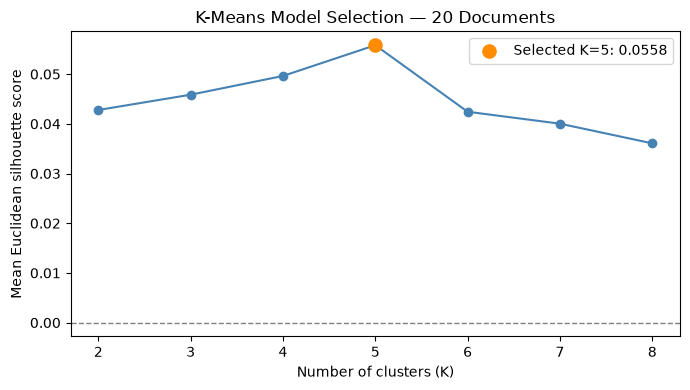

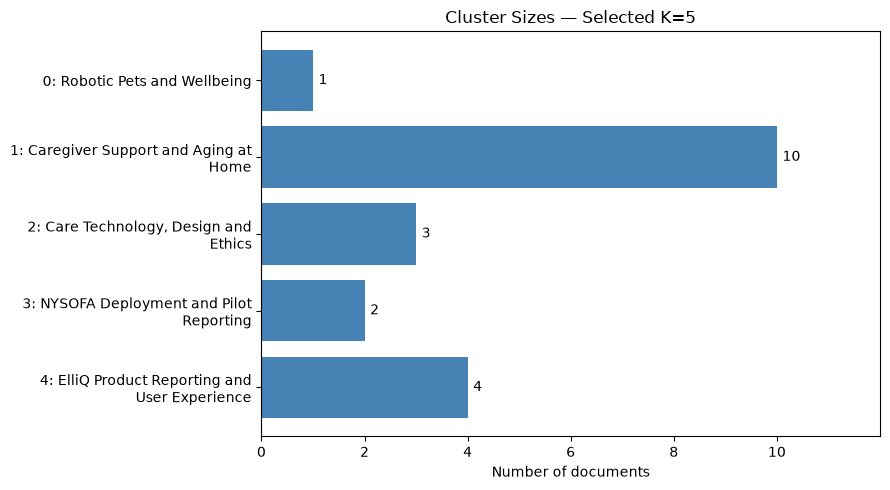

In [6]:
import matplotlib.pyplot as plt
from textwrap import fill

clustering_dir = Path("data") / "week6_clustering"
clustering_figure_dir = clustering_dir / "figures"
clustering_figure_dir.mkdir(parents=True, exist_ok=True)

# Figure 1: Compare all tested K values.
selected_score = float(
    cluster_comparison.set_index("k").loc[
        selected_k, "silhouette_score"
    ]
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    cluster_comparison["k"],
    cluster_comparison["silhouette_score"],
    marker="o",
    color="steelblue"
)

ax.scatter(
    selected_k,
    selected_score,
    color="darkorange",
    s=90,
    zorder=3,
    label=f"Selected K={selected_k}: {selected_score:.4f}"
)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(cluster_comparison["k"])
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Mean Euclidean silhouette score")
ax.set_title("K-Means Model Selection — 20 Documents")
ax.legend()
fig.tight_layout()

fig.savefig(
    clustering_figure_dir / "W06_KMeans_Silhouette_Comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Figure 2: Show cluster sizes.
plot_profiles = cluster_profiles.sort_values("cluster")

plot_labels = [
    f"{row.cluster}: {fill(row.cluster_name, width=30)}"
    for row in plot_profiles.itertuples()
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    plot_labels,
    plot_profiles["document_count"],
    color="steelblue"
)

ax.bar_label(bars, padding=4, fmt="%d")
ax.invert_yaxis()
ax.set_xlim(0, plot_profiles["document_count"].max() + 2)
ax.set_xticks(
    range(0, int(plot_profiles["document_count"].max()) + 1, 2)
)
ax.set_xlabel("Number of documents")
ax.set_title(f"Cluster Sizes — Selected K={selected_k}")
fig.tight_layout()

fig.savefig(
    clustering_figure_dir / "W06_KMeans_Cluster_Sizes.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Business Implications

| Cluster | Implication for Further Investigation |
|---|---|
| 0 — Robotic Pets and Wellbeing | Compare simple companion devices with more complex robots on user acceptance and caregiver effort. One article is insufficient to establish a market opportunity. |
| 1 — Caregiver Support and Aging at Home | Test whether reminders, daily engagement, and family updates address caregivers' priorities. Company messaging identifies proposed benefits, not independently validated demand. |
| 2 — Care Technology, Design and Ethics | For Fari, distinguish development targets from demonstrated capabilities. Evaluate privacy controls, human oversight, and added caregiver workload alongside technical performance. |
| 3 — NYSOFA Deployment and Pilot Reporting | Examine institutional pilot design, onboarding, sustained engagement, and outcome measurement. Both articles concern the same program and are not independent replications. |
| 4 — ElliQ Product Reporting and User Experience | Use issues described in the collected reviews to build usability checks covering conversation, video calls, reliability, and emergency-support expectations. Confirm their current relevance before using them as competitive claims. |

These implications combine cluster organization with article review.
Cluster membership alone does not establish product effectiveness,
customer demand, or investment value.

## Export Clustering Results

Export model comparisons, named profiles, document assignments,
representative articles, centroid terms, and metadata cross-tabulations.

Save the selected centroids and verify exported files by reloading them.
All output paths are relative to the project folder.

In [7]:
# Store top terms and their centroid weights in a reusable table.
top_term_rows = []

for cluster_id in range(selected_k):
    centroid = selected_kmeans.cluster_centers_[cluster_id]
    top_positions = np.argsort(-centroid, kind="stable")[:10]

    for rank, position in enumerate(top_positions, start=1):
        top_term_rows.append({
            "cluster": cluster_id,
            "cluster_name": CLUSTER_NAMES[cluster_id],
            "term_rank": rank,
            "matrix_column": int(position),
            "term": terms[position],
            "centroid_weight": float(centroid[position])
        })

cluster_top_terms = pd.DataFrame(top_term_rows)

# Export document metadata without duplicating full article text.
cluster_assignments = cluster_documents[
    [
        "matrix_row",
        "document_id",
        "title",
        "source_name",
        "source_category",
        "source_url",
        "dominant_topic_label",
        "cluster",
        "cluster_name",
        "distance_to_centroid"
    ]
].copy()

clustering_exports = {
    "W06_KMeans_Model_Comparison.csv": cluster_comparison,
    "W06_KMeans_Cluster_Profiles.csv": cluster_profiles,
    "W06_KMeans_Document_Assignments.csv": cluster_assignments,
    "W06_KMeans_Representative_Documents.csv":
        representative_documents,
    "W06_KMeans_Top_Terms.csv": cluster_top_terms,
    "W06_KMeans_Source_Counts.csv":
        cluster_source_counts.reset_index(),
    "W06_KMeans_LDA_Topic_Counts.csv":
        cluster_topic_counts.reset_index()
}

clustering_dir.mkdir(parents=True, exist_ok=True)

for filename, table in clustering_exports.items():
    # CSV does not retain column-axis metadata.
    table = table.rename_axis(columns=None).reset_index(drop=True)
    output_path = clustering_dir / filename

    table.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    reloaded = pd.read_csv(
        output_path,
        encoding="utf-8-sig",
        keep_default_na=False
    )

    pd.testing.assert_frame_equal(
        table,
        reloaded,
        check_dtype=False,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12
    )

    print(f"Export verified: {filename}")

# Save centroids in the original vocabulary-column order.
centroids_path = clustering_dir / "W06_KMeans_Centroids.npy"

np.save(
    centroids_path,
    selected_kmeans.cluster_centers_,
    allow_pickle=False
)

np.testing.assert_allclose(
    np.load(centroids_path, allow_pickle=False),
    selected_kmeans.cluster_centers_,
    rtol=1e-12,
    atol=1e-12
)

print("Export verified: W06_KMeans_Centroids.npy")
print("\nClustering result exports completed.")

Export verified: W06_KMeans_Model_Comparison.csv
Export verified: W06_KMeans_Cluster_Profiles.csv
Export verified: W06_KMeans_Document_Assignments.csv
Export verified: W06_KMeans_Representative_Documents.csv
Export verified: W06_KMeans_Top_Terms.csv
Export verified: W06_KMeans_Source_Counts.csv
Export verified: W06_KMeans_LDA_Topic_Counts.csv
Export verified: W06_KMeans_Centroids.npy

Clustering result exports completed.
